# Loop worked example: composition → Track A range → Track B prediction → ledger row → held-back measured value
La(Fe,Si)₁₃ parent and its Ni and Cr members (Moreno-Ramírez et al., Acta Mater. 160 (2018) 137; 175 (2019) 406).
23 Nov 2026. Everything here is **retrospective, blinded by procedure only**: the 12 measured values were already evaluated on 12 Nov (ledger L001/L002), so the held-back step documents a procedure and adds no new evidence about the model. Decisions D25–D29.

Data: the measured values are from the published work of L. M. Moreno-Ramírez, V. Franco and co-authors (refs above), as recorded in the NIMS database and digitised from the figures. We thank V. Franco and L. M. Moreno-Ramírez for discussion.

In [1]:
import json, hashlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
D = Path('data')
meas = pd.read_csv(D/'Heldout_12_Measured_Values_20261123.csv')
pT = pd.read_csv(D/'predictions_T_tr.csv'); pS = pd.read_csv(D/'predictions_dS.csv')
Dself = pd.read_csv(D/'D_self.csv'); Dband = pd.read_csv(D/'D_band.csv')
man = json.loads((D/'manifest.json').read_text())
# the frozen predictions must still match the manifest
for name,h in man['outputs'].items():
    assert hashlib.sha256((D/name).read_bytes()).hexdigest()==h, name
print('frozen predictions match the manifest; training rows:', man['n_train'])

frozen predictions match the manifest; training rows: {'T_tr': 967, 'dS': 1374}


## 1. Composition
Parent LaFe₁₁.₆Si₁.₄ (x_Si = 1.4); Ni members nominal 0.1–0.4; Cr members labelled by the EDX Cr content of the paper (not nominal). 12 points: Ni 323–327, Cr 375–381.

In [2]:
meas[['point','series','nims_id','sample_label','Tc_K_NIMS','abs_dS_NIMS_J_kg_K']]

,point,series,nims_id,sample_label,Tc_K_NIMS,abs_dS_NIMS_J_kg_K
0,1,Ni,323,nominal x=0,194.2,19.1
1,2,Ni,324,nominal x=0.1,193.6,19.0
2,3,Ni,325,nominal x=0.2,197.9,12.0
3,4,Ni,326,nominal x=0.3,205.4,8.4
4,5,Ni,327,nominal x=0.4,214.0,4.3
5,6,Cr,375,sample label x=0 (= EDX Cr content per Table 1...,188.3,22.4
6,7,Cr,376,sample label x=0.12 (= EDX Cr content per Tabl...,188.7,21.4
7,8,Cr,377,sample label x=0.21 (= EDX Cr content per Tabl...,184.0,21.1
8,9,Cr,378,sample label x=0.35 (= EDX Cr content per Tabl...,178.9,17.0
9,10,Cr,379,sample label x=0.42 (= EDX Cr content per Tabl...,175.3,14.9


## 2. Track A range (parent only)
Driving-force descriptor D of the CALPHAD reconstruction for LaFe₁₃₋ₓSiₓ (ledger L005, validity **inconclusive**). It is a range for the parent, not a prediction, and it is not used to adjust the Track B result. The band is 20 combinations of binary descriptions; it splits by the La–Si file (Zho versus Xu). **Track A is not applicable to the Ni and Cr members**: the descriptor works on binary edges and has no dopants.

In [3]:
b = Dband[Dband.T_C==1150].copy()
b['lasi'] = b.tdb.str.extract(r'(LaSi-\d+\w+)')
print('x=1.4, 1150 C: self', Dself.query('x==1.4 and T_C==1150').D_J_per_mol_atom.iloc[0], 'J/mol-atom')
print(b[b.x==1.4].groupby('lasi').D_J_per_mol_atom.agg(['min','max','count']))

x=1.4, 1150 C: self 1556.5 J/mol-atom
               min     max  count
lasi                             
LaSi-10Zho  1556.4  1820.2     10
LaSi-20Xu   4748.9  5304.0     10


## 3. Track B prediction (frozen before the measured values are joined)
Snapshot v2 recipe (`evaluate.py`: mean, ridge, GBR; NIMS-only training; the two test papers excluded). Primary models: ridge for Tc, GBR for |ΔS|, chosen after the 12 Nov baselines were known. Criteria: Tc MAE ≤ 10 K, |ΔS| MAE ≤ 4 J/kg/K (`Heldout_Blinded_Criteria_20261123.md`).

In [4]:
jT = pT.merge(meas[['nims_id','series','Tc_K_NIMS']], on='nims_id')
jS = pS.merge(meas[['nims_id','series','abs_dS_NIMS_J_kg_K']], on='nims_id')
mae = lambda j,c: {m: round(float((j['pred_'+m]-j[c]).abs().mean()),2) for m in ('mean','ridge','gbr')}
resT, resS = mae(jT,'Tc_K_NIMS'), mae(jS,'abs_dS_NIMS_J_kg_K')
print('Tc  MAE (K):', resT, 'primary ridge ->', 'PASS' if resT['ridge']<=10 else 'FAIL')
print('|dS| MAE   :', resS, 'primary gbr   ->', 'PASS' if resS['gbr']<=4 else 'FAIL')

Tc  MAE (K): {'mean': 46.89, 'ridge': 7.47, 'gbr': 9.34} primary ridge -> PASS
|dS| MAE   : {'mean': 5.46, 'ridge': 4.83, 'gbr': 3.16} primary gbr   -> PASS


In [5]:
# Sensitivity: paper fit-law values (where the paper gives them) instead of the NIMS digitised values
# Paper values exist for Tc of the 5 Ni points and for |dS| of the 7 Cr points; the other points are not tabulated.
m2 = meas.copy()
m2['Tc_use'] = m2.Tc_K_paper_fit.fillna(m2.Tc_K_NIMS); m2['dS_use'] = m2.abs_dS_paper_fit_J_kg_K.fillna(m2.abs_dS_NIMS_J_kg_K)
kT = pT.merge(m2[['nims_id','Tc_use']], on='nims_id'); kS = pS.merge(m2[['nims_id','dS_use']], on='nims_id')
print('Tc  MAE ridge, paper values where available:', round(float((kT.pred_ridge-kT.Tc_use).abs().mean()),2), 'K  (NIMS only:', resT['ridge'], ')')
print('|dS| MAE gbr, paper values where available :', round(float((kS.pred_gbr-kS.dS_use).abs().mean()),2), '    (NIMS only:', resS['gbr'], ')')


Tc  MAE ridge, paper values where available: 7.77 K  (NIMS only: 7.47 )
|dS| MAE gbr, paper values where available : 3.12     (NIMS only: 3.16 )


## 4. Ledger rows
L011/L012 were written as `pending` with the hashes of the frozen predictions; L013/L014 are the append rows after the join (the pending rows are not edited). The frozen 19 Nov ledger (L001–L010) is read unchanged.

In [6]:
led = pd.concat([pd.read_csv(D/'WP6_ledger_v0_merged_DRAFT_20261119.csv'), pd.read_csv(D/'WP6_ledger_append_pending_20261123.csv'), pd.read_csv(D/'WP6_ledger_append_unblind_20261123.csv')])
led[led.entry_id.isin(['L011','L012','L013','L014'])][['entry_id','target','metric_result','success_flag','notes']]

,entry_id,target,metric_result,success_flag,notes
0,L011,Tc (K),NaN,pending,Predictions identical to L001/L002 (same model...
1,L012,"|dS| (J/kg/K), 1.9 T",NaN,pending,Predictions identical to L001/L002 (same model...
0,L013,Tc (K),"MAE 7.47 K (ridge, primary); GBR 9.34; mean 46.89",pass,"Retrospective, blinded by procedure only; iden..."
1,L014,"|dS| (J/kg/K), 1.9 T","MAE 3.16 (gbr, primary); ridge 4.83; mean 5.46",pass,"Retrospective, blinded by procedure only; iden..."


## 5. One figure
Left: the frame of the loop with its real outcomes (branches i–iii). Right: Track A range for the parent, and predicted against measured for the 12 held-out points.

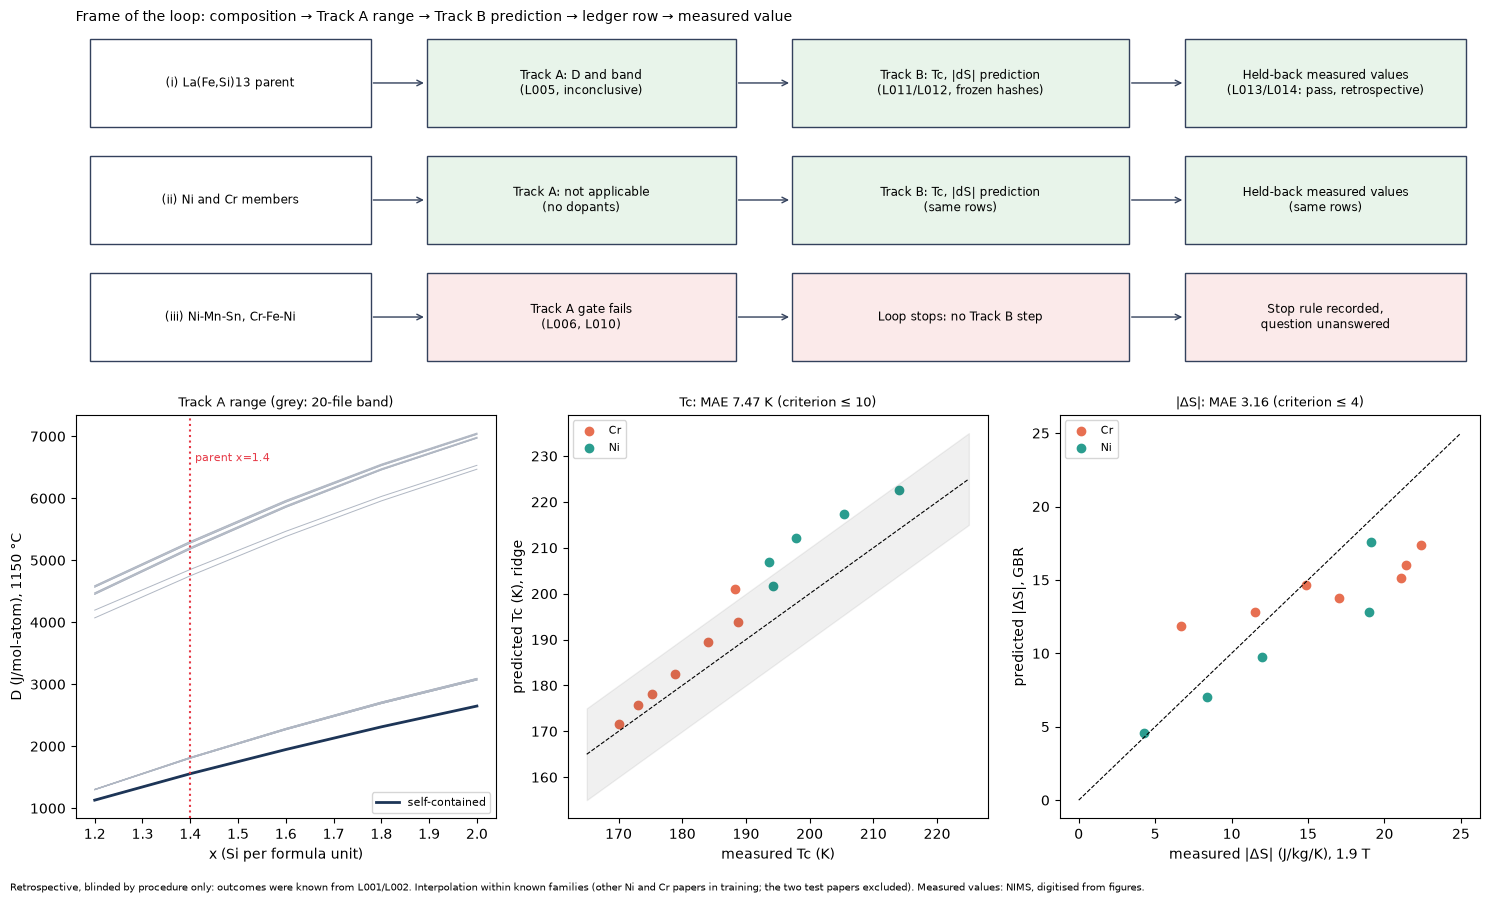

In [7]:
fig = plt.figure(figsize=(15,9))
gs = fig.add_gridspec(2,3, height_ratios=[1,1.15])
# --- frame (B) ---
ax = fig.add_subplot(gs[0,:]); ax.axis('off'); ax.set_xlim(0,10); ax.set_ylim(0,3.6)
def box(x,y,w,h,t,fc='#eef2f7'):
    ax.add_patch(plt.Rectangle((x,y),w,h,fc=fc,ec='#33415c',lw=1)); ax.text(x+w/2,y+h/2,t,ha='center',va='center',fontsize=8.5)
def arr(x0,y0,x1,y1): ax.annotate('',xy=(x1,y1),xytext=(x0,y0),arrowprops=dict(arrowstyle='->',color='#33415c'))
rows=[(2.6,'(i) La(Fe,Si)13 parent','Track A: D and band\n(L005, inconclusive)','Track B: Tc, |dS| prediction\n(L011/L012, frozen hashes)','Held-back measured values\n(L013/L014: pass, retrospective)','#e8f4ea'),
      (1.4,'(ii) Ni and Cr members','Track A: not applicable\n(no dopants)','Track B: Tc, |dS| prediction\n(same rows)','Held-back measured values\n(same rows)','#e8f4ea'),
      (0.2,'(iii) Ni-Mn-Sn, Cr-Fe-Ni','Track A gate fails\n(L006, L010)','Loop stops: no Track B step','Stop rule recorded,\nquestion unanswered','#fbeaea')]
for y,a,b_,c,d,col in rows:
    box(0.1,y,2.0,0.9,a,'#ffffff'); box(2.5,y,2.2,0.9,b_,col); box(5.1,y,2.4,0.9,c,col); box(7.9,y,2.0,0.9,d,col)
    arr(2.1,y+.45,2.5,y+.45); arr(4.7,y+.45,5.1,y+.45); arr(7.5,y+.45,7.9,y+.45)
ax.set_title('Frame of the loop: composition → Track A range → Track B prediction → ledger row → measured value', fontsize=10, loc='left')
# --- Track A ---
a1 = fig.add_subplot(gs[1,0])
for t,g in Dband[Dband.T_C==1150].groupby('tdb'):
    a1.plot(g.x,g.D_J_per_mol_atom,color='#b0b7c3',lw=.7)
s = Dself[Dself.T_C==1150]; a1.plot(s.x,s.D_J_per_mol_atom,color='#1d3557',lw=2,label='self-contained')
a1.axvline(1.4,ls=':',color='#e63946'); a1.text(1.41,6600,'parent x=1.4',color='#e63946',fontsize=8)
a1.set_xlabel('x (Si per formula unit)'); a1.set_ylabel('D (J/mol-atom), 1150 °C'); a1.set_title('Track A range (grey: 20-file band)',fontsize=9); a1.legend(fontsize=8)
# --- Tc ---
col={'Ni':'#2a9d8f','Cr':'#e76f51'}
a2 = fig.add_subplot(gs[1,1])
for s_,g in jT.groupby('series'): a2.scatter(g.Tc_K_NIMS,g.pred_ridge,c=col[s_],label=s_)
lo,hi=165,225; a2.plot([lo,hi],[lo,hi],'k--',lw=.8); a2.fill_between([lo,hi],[lo-10,hi-10],[lo+10,hi+10],color='k',alpha=.06)
a2.set_xlabel('measured Tc (K)'); a2.set_ylabel('predicted Tc (K), ridge'); a2.set_title(f"Tc: MAE {resT['ridge']} K (criterion ≤ 10)",fontsize=9); a2.legend(fontsize=8)
# --- dS ---
a3 = fig.add_subplot(gs[1,2])
for s_,g in jS.groupby('series'): a3.scatter(g.abs_dS_NIMS_J_kg_K,g.pred_gbr,c=col[s_],label=s_)
a3.plot([0,25],[0,25],'k--',lw=.8); a3.set_xlabel('measured |ΔS| (J/kg/K), 1.9 T'); a3.set_ylabel('predicted |ΔS|, GBR')
a3.set_title(f"|ΔS|: MAE {resS['gbr']} (criterion ≤ 4)",fontsize=9); a3.legend(fontsize=8)
fig.text(0.01,0.005,'Retrospective, blinded by procedure only: outcomes were known from L001/L002. Interpolation within known families (other Ni and Cr papers in training; the two test papers excluded). Measured values: NIMS, digitised from figures.',fontsize=7.5)
plt.tight_layout(rect=(0,0.02,1,1)); fig.savefig('loop_worked_example.png',dpi=200); plt.show()

## Limits
- The held-out test is interpolation within known families; it is not a test of new compounds.
- Track A's descriptor is inconclusive against the own microstructure data and is essentially a function of x; it has no temperature dependence and does not enter the prediction.
- Thresholds were set after the 12 Nov baselines; the outcome was known. True prospective rows wait for new samples (D11).
- Environment of this run: see `manifest.json`; the 12 Nov environment was not recorded.